# 1. Setup and Data Loading


Import the libraries and define the main project paths.

## 1.1 Imports and Paths

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

In [2]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
INTERIM_DATA_DIR = PROJECT_ROOT / "data" / "interim"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"

FIGURES_DIR = OUTPUTS_DIR / "figures"
MODELS_DIR = OUTPUTS_DIR / "models"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

METADATA_PATH = (
    INTERIM_DATA_DIR / "final_clean_metadata.csv"
)

## 1.2 Load Metadata

Load the cleaned dataset metadata created in the previous notebook.

In [3]:
df = pd.read_csv(METADATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (16962, 12)


,sequence,image_sequence,file,label,site,date,camera,project_class,split,zip_path,found_in_zip,quality_status
0,77378,image2,1106150852100835S082.jpg,BIRD,835,6/11/2015 8:52,S08,BIRD,train,images/1106150852100835S082.jpg,False,keep
1,41636,image3,210916072714043as433.jpg,BIRD,043a,9/21/2016 7:27,s43,BIRD,train,images/210916072714043as433.jpg,False,keep
2,58458,image2,240916111910017as082.jpg,BIRD,017a,9/24/2016 11:19,s08,BIRD,train,images/240916111910017as082.jpg,False,keep
3,36044,image2,161016171542019b9705.jpg,BIRD,019b,10/16/2016 17:15,970,BIRD,train,images/161016171542019b9705.jpg,False,keep
4,38018,image2,021116133626027cs082.jpg,BIRD,027c,11/2/2016 13:36,s08,BIRD,train,images/021116133626027cs082.jpg,False,keep


In [4]:
pd.crosstab(
    df["project_class"],
    df["split"]
)

split,test,train,val
project_class,,,
BIRD,448,1869,419
CAT,450,1999,402
EMPTY,444,1904,418
HEDGEHOG,450,1953,396
POSSUM,450,2064,450
RODENT,450,2011,385


#### Class Balance After Cleaning

The final dataset has small differences in class size because low-quality images were removed.

The class distribution is still relatively balanced, so no additional resampling is applied.

## 1.3 Define Classes and Device

Define the six classes used in the classification model.

In [5]:
CLASS_NAMES = [
    "BIRD",
    "CAT",
    "EMPTY",
    "HEDGEHOG",
    "POSSUM",
    "RODENT"
]

CLASS_TO_INDEX = {
    cls: idx
    for idx, cls in enumerate(CLASS_NAMES)
}

CLASS_TO_INDEX

{'BIRD': 0, 'CAT': 1, 'EMPTY': 2, 'HEDGEHOG': 3, 'POSSUM': 4, 'RODENT': 5}


Use a GPU if one is available. Otherwise, use the CPU.

In [6]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce RTX 5060 Laptop GPU


# 2. Data Pipeline

## 2.1 Image Transforms


Define image transformations for training, validation, and testing.

Training images use light augmentation. Validation and test images only use resizing and normalization.

In [48]:
IMAGE_SIZE = 1000

train_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## 2.2 Dataset Class


Create a custom PyTorch dataset to load images and class labels from the metadata.

In [8]:
class CameraTrapDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = (
            self.image_dir
            / row["split"]
            / row["project_class"]
            / row["file"]
        )

        image = Image.open(image_path).convert("RGB")

        label = CLASS_TO_INDEX[row["project_class"]]

        if self.transform:
            image = self.transform(image)

        return image, label

## 2.3 DataLoaders

Split the metadata into training, validation, and test sets.

In [9]:
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 11800
Validation: 2470
Test: 2692


## 2.5 Create Image Cache

In [54]:
CACHE_DATA_DIR = PROJECT_ROOT / "data" / "cache_1000"

CACHE_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

cache_resize = transforms.Resize(1000)

In [55]:
from tqdm.auto import tqdm

for _, row in tqdm(
    df.iterrows(),
    total=len(df)
):
    source_path = (
        PROCESSED_DATA_DIR
        / row["split"]
        / row["project_class"]
        / row["file"]
    )

    target_path = (
        CACHE_DATA_DIR
        / row["split"]
        / row["project_class"]
        / row["file"]
    )

    # Skip images already cached
    if target_path.exists():
        continue

    target_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    with Image.open(source_path) as image:
        image = image.convert("RGB")

        # Resize the shorter side to 1000 pixels
        image = cache_resize(image)

        image.save(
            target_path,
            quality=90
        )

  0%|          | 0/16962 [00:00<?, ?it/s]

## 2.6 Use Cached Images

In [57]:
train_dataset = CameraTrapDataset(
    train_df,
    CACHE_DATA_DIR,
    transform=train_transform
)

val_dataset = CameraTrapDataset(
    val_df,
    CACHE_DATA_DIR,
    transform=eval_transform
)

test_dataset = CameraTrapDataset(
    test_df,
    CACHE_DATA_DIR,
    transform=eval_transform
)

## 2.7 Use a Safe DataLoader

In [66]:
BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

## 2.8 Check Cached Image

In [60]:
row = train_df.iloc[0]

test_path = (
    CACHE_DATA_DIR
    / row["split"]
    / row["project_class"]
    / row["file"]
)

print("Exists:", test_path.exists())

with Image.open(test_path) as image:
    print("Image size:", image.size)

Exists: True
Image size: (1333, 1000)


## 2.9 Test Loading Speed

In [61]:
import time

start = time.time()

for i, (images, labels) in enumerate(train_loader):
    if i == 9:
        break

elapsed = time.time() - start

print(f"10 batches: {elapsed:.1f} seconds")

10 batches: 22.8 seconds


# 3. Baseline CNN

Create a simple CNN as a baseline model.

The baseline gives a simple reference before using a stronger pretrained model.

## 3.1 Model


In [72]:
class SimpleCNN(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convert different image sizes to a fixed feature size
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [68]:
baseline_model = SimpleCNN(
    num_classes=NUM_CLASSES
).to(device)

images, labels = next(iter(train_loader))

print("Input:", images.shape)

outputs = baseline_model(
    images.to(device)
)

print("Output:", outputs.shape)

Input: torch.Size([2, 3, 1000, 1333])
Output: torch.Size([2, 6])


In [73]:
NUM_CLASSES = len(CLASS_NAMES)

baseline_model = SimpleCNN(
    num_classes=NUM_CLASSES
).to(device)

baseline_model

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=6, bias=True)
  )
)

## 3.2 Loss and Optimizer

Use cross-entropy loss for multi-class classification. Cross-Entropy Loss measures how far the model's prediction deviates from the correct answer.

Use Adam to update the model weights. Adam is an optimizer. It adjusts the weights in the neural network based on the errors and gradients calculated by cross-entropy, enabling the model to make more accurate predictions in the next round:

In [74]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=0.001
)

## 3.3 Training and Validation Functions

Create functions for model training and validation.

In [75]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


def evaluate_model(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

## 3.4 Train the Model

Train the baseline CNN for five epochs and record the training and validation results.

In [76]:
import time

NUM_EPOCHS = 5

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    train_loss, train_accuracy = train_one_epoch(
        baseline_model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate_model(
        baseline_model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {epoch_time / 60:.1f} min"
    )

Epoch 1/5 | Train Loss: 1.5139 | Train Acc: 0.3155 | Val Loss: 1.4445 | Val Acc: 0.3198 | Time: 17.4 min
Epoch 2/5 | Train Loss: 1.3926 | Train Acc: 0.3908 | Val Loss: 1.3666 | Val Acc: 0.3599 | Time: 16.6 min
Epoch 3/5 | Train Loss: 1.3210 | Train Acc: 0.4510 | Val Loss: 1.4046 | Val Acc: 0.4146 | Time: 16.9 min
Epoch 4/5 | Train Loss: 1.2610 | Train Acc: 0.4814 | Val Loss: 1.5279 | Val Acc: 0.3830 | Time: 18.0 min
Epoch 5/5 | Train Loss: 1.2186 | Train Acc: 0.5039 | Val Loss: 1.5861 | Val Acc: 0.3429 | Time: 21.8 min


## 3.5 Baseline Result

The high-resolution baseline CNN reached its best validation accuracy of 41.46% at epoch 3.

Training accuracy continued to increase after epoch 3, while validation accuracy decreased and validation loss increased. This suggests overfitting.

The high-resolution input performed better than the earlier low-resolution baseline, but the simple CNN still had limited classification performance.

## 3.6 Plot Learning Curves

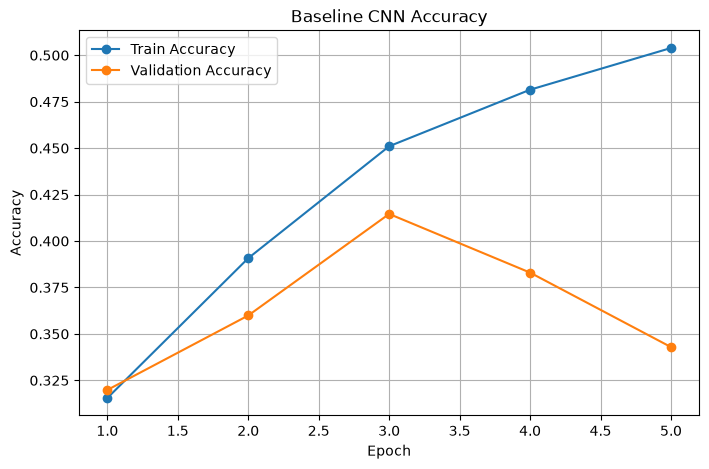

In [77]:
epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN Accuracy")
plt.legend()
plt.grid()

plt.show()

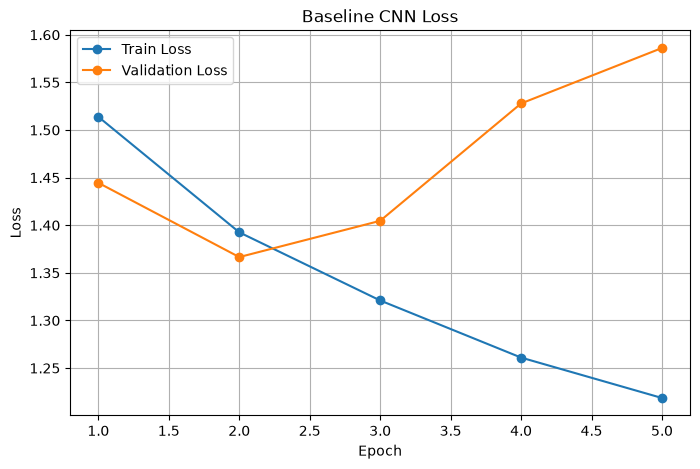

In [78]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN Loss")
plt.legend()
plt.grid()

plt.show()

The baseline CNN showed clear overfitting after the first few epochs.

Training accuracy continued to increase, while validation accuracy peaked at 41.46% at epoch 3 and then decreased.

Validation loss also increased in later epochs, showing that the model did not generalize well to unseen images.

# 4. ResNet18

Use a pretrained ResNet18 model and fine-tune it for the six wildlife classes.

## 4.1 Load Pretrained Model

In [79]:
from torchvision.models import ResNet18_Weights

weights = ResNet18_Weights.DEFAULT

resnet_model = models.resnet18(
    weights=weights
)

resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    NUM_CLASSES
)

resnet_model = resnet_model.to(device)

## 4.2 Loss and Optimizer

Use cross-entropy loss and Adam for fine-tuning.

In [81]:
resnet_criterion = nn.CrossEntropyLoss()

resnet_optimizer = torch.optim.Adam(
    resnet_model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

scaler = torch.amp.GradScaler("cuda")

## 4.3 Training Functions

Use mixed precision to reduce GPU memory use and speed up training.

In [82]:
def train_one_epoch_amp(
    model,
    loader,
    criterion,
    optimizer,
    device,
    scaler
):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        with torch.amp.autocast(
            device_type="cuda"
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


def evaluate_model_amp(
    model,
    loader,
    criterion,
    device
):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            with torch.amp.autocast(
                device_type="cuda"
            ):
                outputs = model(images)
                loss = criterion(
                    outputs,
                    labels
                )

            total_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

## 4.4 Train ResNet18

Train ResNet18 for five epochs and save the best validation model.

In [83]:
import time

NUM_EPOCHS = 5

resnet_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0

BEST_MODEL_PATH = (
    MODELS_DIR
    / "best_resnet18_high_res.pth"
)

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    train_loss, train_accuracy = train_one_epoch_amp(
        resnet_model,
        train_loader,
        resnet_criterion,
        resnet_optimizer,
        device,
        scaler
    )

    val_loss, val_accuracy = evaluate_model_amp(
        resnet_model,
        val_loader,
        resnet_criterion,
        device
    )

    resnet_history["train_loss"].append(
        train_loss
    )

    resnet_history["train_accuracy"].append(
        train_accuracy
    )

    resnet_history["val_loss"].append(
        val_loss
    )

    resnet_history["val_accuracy"].append(
        val_accuracy
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet_model.state_dict(),
            BEST_MODEL_PATH
        )

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {epoch_time / 60:.1f} min"
    )

print(
    "\nBest Val Acc:",
    round(best_val_accuracy, 4)
)

print(
    "Saved model:",
    BEST_MODEL_PATH
)

Epoch 1/5 | Train Loss: 1.1785 | Train Acc: 0.5257 | Val Loss: 1.5746 | Val Acc: 0.5356 | Time: 24.8 min
Epoch 2/5 | Train Loss: 0.8199 | Train Acc: 0.6878 | Val Loss: 0.9277 | Val Acc: 0.6818 | Time: 24.5 min
Epoch 3/5 | Train Loss: 0.6645 | Train Acc: 0.7582 | Val Loss: 1.0506 | Val Acc: 0.6842 | Time: 24.0 min
Epoch 4/5 | Train Loss: 0.6018 | Train Acc: 0.7810 | Val Loss: 0.9080 | Val Acc: 0.7126 | Time: 25.1 min
Epoch 5/5 | Train Loss: 0.5607 | Train Acc: 0.7964 | Val Loss: 0.8208 | Val Acc: 0.7134 | Time: 25.1 min

Best Val Acc: 0.7134
Saved model: e:\Code\ai-predator-early-warning\outputs\models\best_resnet18_high_res.pth


## 4.5 Continue Training

Continue training for three more epochs because validation performance is still improving.

In [84]:
TOTAL_EPOCHS = 8

for epoch in range(5, TOTAL_EPOCHS):

    epoch_start = time.time()

    train_loss, train_accuracy = train_one_epoch_amp(
        resnet_model,
        train_loader,
        resnet_criterion,
        resnet_optimizer,
        device,
        scaler
    )

    val_loss, val_accuracy = evaluate_model_amp(
        resnet_model,
        val_loader,
        resnet_criterion,
        device
    )

    resnet_history["train_loss"].append(train_loss)
    resnet_history["train_accuracy"].append(train_accuracy)
    resnet_history["val_loss"].append(val_loss)
    resnet_history["val_accuracy"].append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            resnet_model.state_dict(),
            BEST_MODEL_PATH
        )

    epoch_time = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1}/{TOTAL_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {epoch_time / 60:.1f} min"
    )

print(
    "\nBest Val Acc:",
    round(best_val_accuracy, 4)
)

Epoch 6/8 | Train Loss: 0.5192 | Train Acc: 0.8119 | Val Loss: 1.0522 | Val Acc: 0.6656 | Time: 23.0 min
Epoch 7/8 | Train Loss: 0.4860 | Train Acc: 0.8224 | Val Loss: 0.8367 | Val Acc: 0.7296 | Time: 23.3 min
Epoch 8/8 | Train Loss: 0.4583 | Train Acc: 0.8311 | Val Loss: 0.8418 | Val Acc: 0.6988 | Time: 24.8 min

Best Val Acc: 0.7296


## 4.6 Load Best High-Resolution Model

In [85]:
resnet_model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

resnet_model = resnet_model.to(device)
resnet_model.eval()

print("Best high-resolution ResNet18 loaded.")

Best high-resolution ResNet18 loaded.


## 4.7 Test High-Resolution Model

In [86]:
test_loss, test_accuracy = evaluate_model_amp(
    resnet_model,
    test_loader,
    resnet_criterion,
    device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.9039
Test Accuracy: 0.7047


In [87]:
from sklearn.metrics import classification_report

all_labels = []
all_predictions = []

resnet_model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        with torch.amp.autocast(
            device_type="cuda"
        ):
            outputs = resnet_model(images)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

report = classification_report(
    all_labels,
    all_predictions,
    target_names=CLASS_NAMES,
    digits=4
)

print(report)

              precision    recall  f1-score   support

        BIRD     0.9150    0.4085    0.5648       448
         CAT     0.8967    0.4822    0.6272       450
       EMPTY     0.5186    0.7860    0.6249       444
    HEDGEHOG     0.7491    0.8822    0.8102       450
      POSSUM     0.6558    0.8467    0.7391       450
      RODENT     0.7940    0.8222    0.8079       450

    accuracy                         0.7047      2692
   macro avg     0.7548    0.7046    0.6957      2692
weighted avg     0.7553    0.7047    0.6959      2692



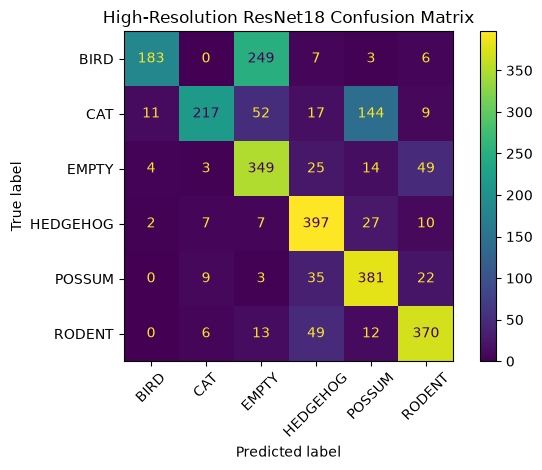

In [88]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    all_labels,
    all_predictions,
    display_labels=CLASS_NAMES,
    xticks_rotation=45
)

plt.title(
    "High-Resolution ResNet18 Confusion Matrix"
)

plt.tight_layout()
plt.show()

# 5. Alert-Level Evaluation

Convert the six wildlife classes into `ALERT` and `NO ALERT`.

`CAT`, `HEDGEHOG`, `POSSUM`, and `RODENT` are treated as alert classes.

`BIRD` and `EMPTY` are treated as no-alert classes.

## 5.1 Convert Classes to Alert Labels

In [90]:
ALERT_CLASSES = {
    "CAT",
    "HEDGEHOG",
    "POSSUM",
    "RODENT"
}

def to_alert_label(class_index):
    class_name = CLASS_NAMES[class_index]

    if class_name in ALERT_CLASSES:
        return 1

    return 0


alert_true = [
    to_alert_label(label)
    for label in all_labels
]

alert_pred = [
    to_alert_label(prediction)
    for prediction in all_predictions
]

## 5.2 Alert Metrics

Evaluate the model as an early-warning system.

Recall is especially important because a false negative means that an alert animal was missed.

In [91]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

alert_accuracy = accuracy_score(
    alert_true,
    alert_pred
)

alert_precision = precision_score(
    alert_true,
    alert_pred
)

alert_recall = recall_score(
    alert_true,
    alert_pred
)

alert_f1 = f1_score(
    alert_true,
    alert_pred
)

print(f"Alert Accuracy:  {alert_accuracy:.4f}")
print(f"Alert Precision: {alert_precision:.4f}")
print(f"Alert Recall:    {alert_recall:.4f}")
print(f"Alert F1-score:  {alert_f1:.4f}")

Alert Accuracy:  0.9276
Alert Precision: 0.9412
Alert Recall:    0.9511
Alert F1-score:  0.9461


## 5.3 Alert Confusion Matrix

Show correct alerts, missed alerts, and false alerts.

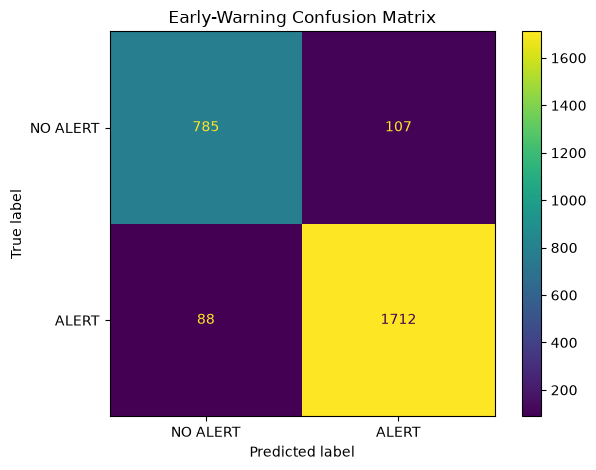

In [92]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    alert_true,
    alert_pred,
    display_labels=[
        "NO ALERT",
        "ALERT"
    ]
)

plt.title(
    "Early-Warning Confusion Matrix"
)

plt.tight_layout()
plt.show()

## 6. Confidence Threshold Analysis

## 6.1 Get Alert Probabilities

Calculate the total probability of all alert classes for each test image.

In [94]:
import torch.nn.functional as F

ALERT_INDICES = [
    CLASS_TO_INDEX["CAT"],
    CLASS_TO_INDEX["HEDGEHOG"],
    CLASS_TO_INDEX["POSSUM"],
    CLASS_TO_INDEX["RODENT"]
]

alert_scores = []
alert_true = []

resnet_model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        with torch.amp.autocast(
            device_type="cuda"
        ):
            outputs = resnet_model(images)

        probabilities = F.softmax(
            outputs,
            dim=1
        )

        # Sum probabilities of all alert classes
        batch_alert_scores = probabilities[
            :,
            ALERT_INDICES
        ].sum(dim=1)

        alert_scores.extend(
            batch_alert_scores.cpu().numpy()
        )

        for label in labels.numpy():
            class_name = CLASS_NAMES[label]

            alert_true.append(
                1 if class_name in ALERT_CLASSES else 0
            )

print("Test images:", len(alert_scores))
print("Alert labels:", len(alert_true))

print(
    "Alert score range:",
    min(alert_scores),
    "to",
    max(alert_scores)
)

Test images: 2692
Alert labels: 2692
Alert score range: 6.74e-05 to 1.0


## 6.2 Test Different Thresholds

In [97]:
from sklearn.metrics import confusion_matrix
thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = []

for threshold in thresholds:

    alert_predictions = [
        1 if score >= threshold else 0
        for score in alert_scores
    ]

    accuracy = accuracy_score(
        alert_true,
        alert_predictions
    )

    precision = precision_score(
        alert_true,
        alert_predictions
    )

    recall = recall_score(
        alert_true,
        alert_predictions
    )

    f1 = f1_score(
        alert_true,
        alert_predictions
    )

    tn, fp, fn, tp = confusion_matrix(
        alert_true,
        alert_predictions
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_alerts": fp,
        "missed_alerts": fn
    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df.round(4)

,threshold,accuracy,precision,recall,f1,false_alerts,missed_alerts
0,0.10,0.8284,0.8024,0.9861,0.8848,437,25
1,0.15,0.8670,0.8443,0.9822,0.9081,326,32
2,0.20,0.8904,0.8731,0.9783,0.9227,256,39
3,0.25,0.9090,0.8981,0.9744,0.9347,199,46
4,0.30,0.9164,0.9095,0.9717,0.9396,174,51
5,0.35,0.9212,0.9179,0.9689,0.9427,156,56
6,0.40,0.9250,0.9250,0.9661,0.9451,141,61
7,0.45,0.9261,0.9306,0.9611,0.9456,129,70
8,0.50,0.9287,0.9355,0.9594,0.9473,119,73
9,0.55,0.9272,0.9383,0.9539,0.9460,113,83


## 6.3 Threshold Trade-off

Compare precision, recall, and F1-score across different alert thresholds.

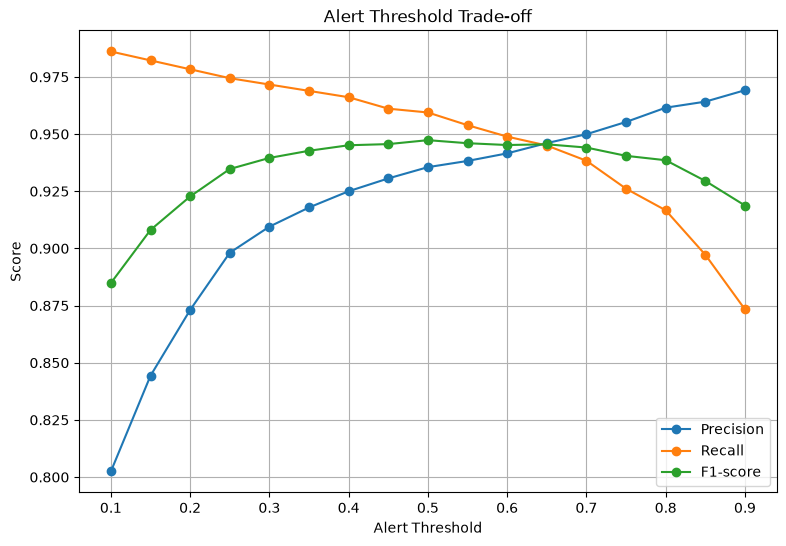

In [98]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Alert Threshold")
plt.ylabel("Score")
plt.title("Alert Threshold Trade-off")
plt.legend()
plt.grid()

plt.show()

## 6.4 Alert Errors

Compare false alerts and missed alerts at different thresholds.

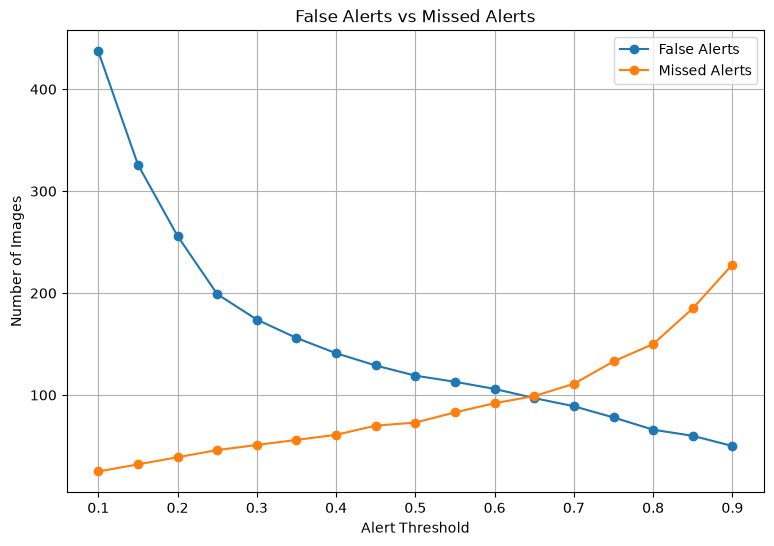

In [99]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["false_alerts"],
    marker="o",
    label="False Alerts"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["missed_alerts"],
    marker="o",
    label="Missed Alerts"
)

plt.xlabel("Alert Threshold")
plt.ylabel("Number of Images")
plt.title("False Alerts vs Missed Alerts")
plt.legend()
plt.grid()

plt.show()

## 6.5 Select Alert Threshold

A threshold of 0.40 is selected for the early-warning prototype.

At this threshold, alert recall is 96.61% and F1-score is 94.51%.

Compared with the default threshold of 0.50, this setting reduces missed alerts from 73 to 61, while increasing false alerts from 119 to 141.

This trade-off is reasonable for an early-warning system because missing an alert animal may be more costly than generating an extra alert.

## 6.6 Compare Alert Score Methods

Compare two ways to calculate alert confidence:

- Sum method: add the probabilities of all alert classes.
- Max method: use only the highest probability among alert classes.

In [104]:
sum_alert_scores = []
max_alert_scores = []
alert_true = []

resnet_model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        with torch.amp.autocast(
            device_type="cuda"
        ):
            outputs = resnet_model(images)

        probabilities = F.softmax(
            outputs,
            dim=1
        )

        alert_probabilities = probabilities[
            :,
            ALERT_INDICES
        ]

        # Method 1: Sum all alert probabilities
        batch_sum_scores = alert_probabilities.sum(
            dim=1
        )

        # Method 2: Use the highest alert probability
        batch_max_scores = alert_probabilities.max(
            dim=1
        ).values

        sum_alert_scores.extend(
            batch_sum_scores.cpu().numpy()
        )

        max_alert_scores.extend(
            batch_max_scores.cpu().numpy()
        )

        for label in labels.numpy():
            class_name = CLASS_NAMES[label]

            alert_true.append(
                1 if class_name in ALERT_CLASSES else 0
            )

# 7. Error Analysis

Inspect false alerts and missed alerts to understand common model errors.

In [100]:
SELECTED_THRESHOLD = 0.40

threshold_predictions = np.array([
    1 if score >= SELECTED_THRESHOLD else 0
    for score in alert_scores
])

alert_true_array = np.array(alert_true)

false_alert_indices = np.where(
    (alert_true_array == 0)
    & (threshold_predictions == 1)
)[0]

missed_alert_indices = np.where(
    (alert_true_array == 1)
    & (threshold_predictions == 0)
)[0]

print("False alerts:", len(false_alert_indices))
print("Missed alerts:", len(missed_alert_indices))

False alerts: 141
Missed alerts: 61


## 7.2 Show False Alerts

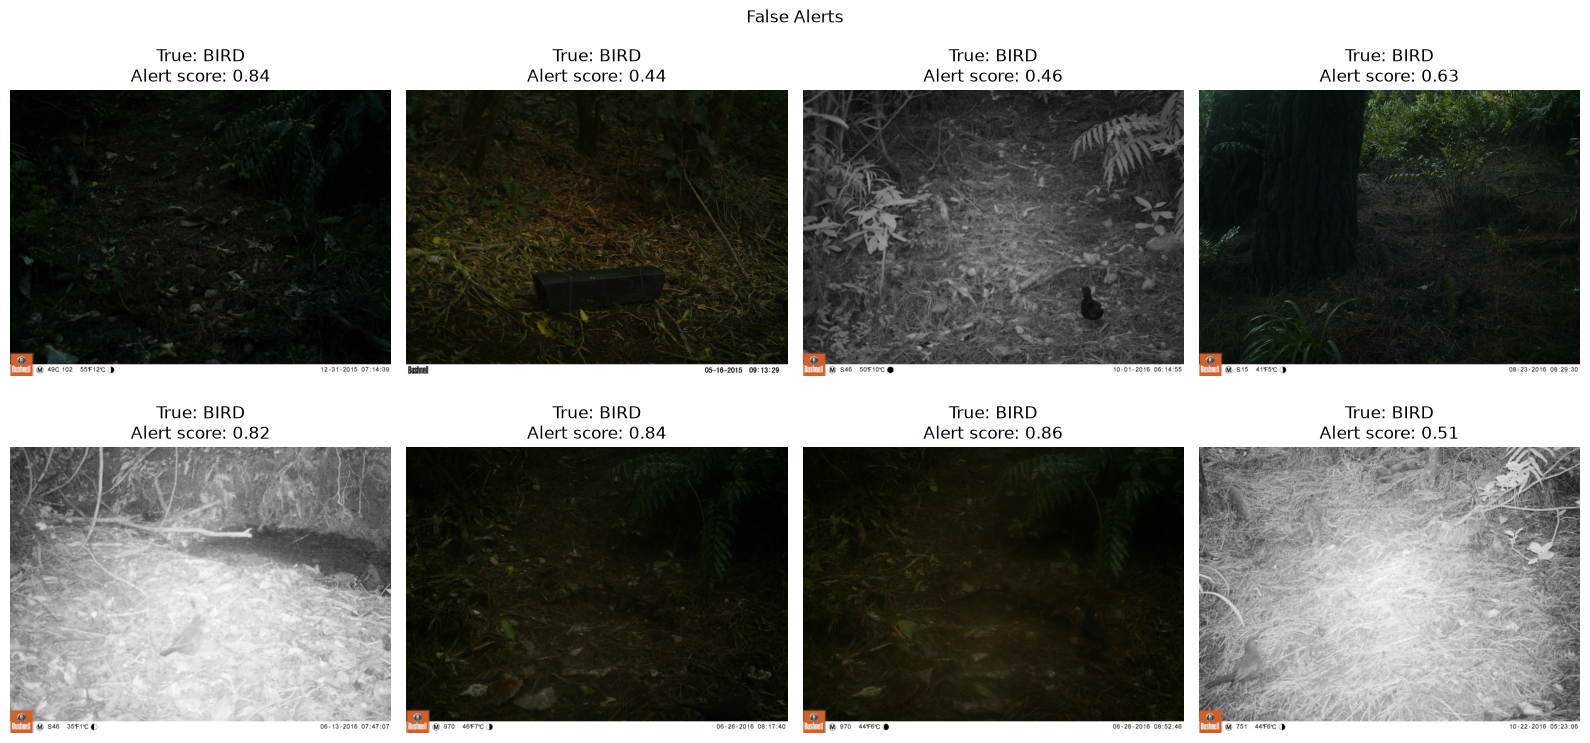

In [102]:
def show_error_images(indices, title, n=8):
    sample_indices = indices[:n]

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(16, 8)
    )

    axes = axes.ravel()

    for ax, idx in zip(
        axes,
        sample_indices
    ):
        row = test_df.iloc[idx]

        image_path = (
            CACHE_DATA_DIR
            / row["split"]
            / row["project_class"]
            / row["file"]
        )

        image = Image.open(image_path)

        ax.imshow(image)

        ax.set_title(
            f"True: {row['project_class']}\n"
            f"Alert score: {alert_scores[idx]:.2f}"
        )

        ax.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_error_images(
    false_alert_indices,
    "False Alerts"
)

## 7.3 Show Missed Alerts

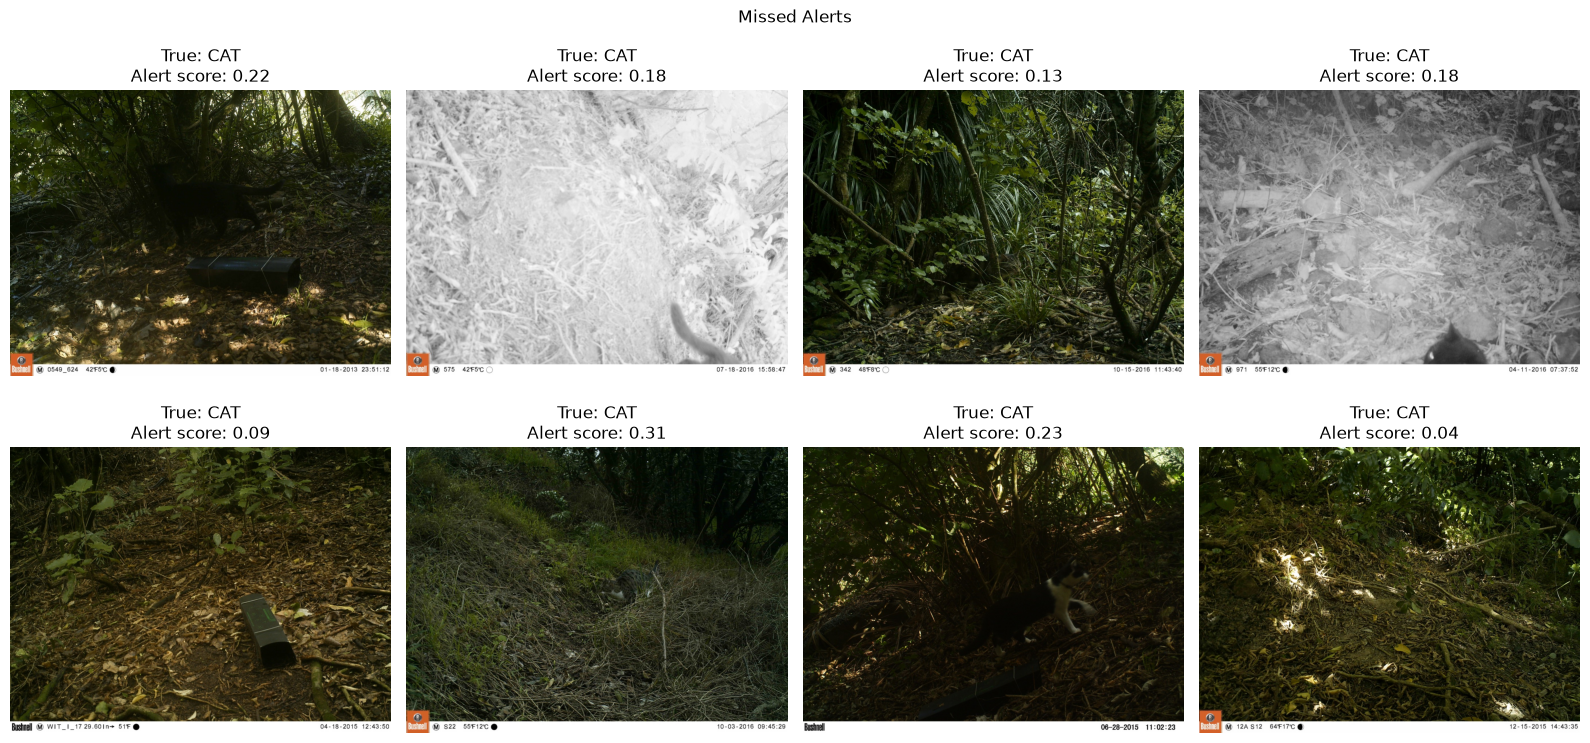

In [103]:
show_error_images(
    missed_alert_indices,
    "Missed Alerts"
)

# 8. Save Results

Save model results and predictions so they can be reused without running inference again.

In [2]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

OUTPUTS_DIR = PROJECT_ROOT / "outputs"
RESULTS_DIR = OUTPUTS_DIR / "results"
MODELS_DIR = OUTPUTS_DIR / "models"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Results:", RESULTS_DIR)
print("Models:", MODELS_DIR)

Results: e:\Code\ai-predator-early-warning\outputs\results
Models: e:\Code\ai-predator-early-warning\outputs\models
